# ANEXO D. Semana 2: machine learning con scikit-learn

Notebook del curso SENA Iniciación a la IA para ADSO 2026. Las explicaciones completas están en la guía, anexo D.

Guarde su copia con **Archivo > Guardar una copia en Drive**.

## D.1 Cargar y explorar los datos

Conjunto "Adult" de OpenML: 48.842 personas con datos de un censo, para predecir si sus ingresos anuales superan 50.000 dólares.

In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

datos = fetch_openml("adult", version=2, as_frame=True)
df = datos.frame
print(df.shape)
print(df["class"].value_counts(normalize=True))
df.head()

(48842, 15)
class
<=50K    0.760718
>50K     0.239282
Name: proportion, dtype: float64


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


Revise: ¿cuántas filas y columnas hay? 48842,
¿qué porcentaje tiene cada clase? <=50K    0.760718
>50K     0.239282,
¿las clases están balanceadas? no

In [2]:
df.info()
print(df.isna().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB
age                  0
workclass         2799
fnlwgt      

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


## D.2 Preparar los datos

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=["class", "fnlwgt"])
y = (df["class"] == ">50K").astype(int)

numericas = X.select_dtypes("number").columns
categoricas = X.select_dtypes(exclude="number").columns

preparar = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), numericas),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("codificar", OneHotEncoder(handle_unknown="ignore"))]), categoricas),
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
  )

print("Datos de entrenamiento:", X_train.shape)

print("Datos de prueba:", X_test.shape)

print("\nDistribución de entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribución de prueba:")
print(y_test.value_counts(normalize=True).round(3))

print("\nValores faltantes en X:")
print(X.isna().sum().sum())


Datos de entrenamiento: (39073, 13)
Datos de prueba: (9769, 13)

Distribución de entrenamiento:
class
0    0.761
1    0.239
Name: proportion, dtype: float64

Distribución de prueba:
class
0    0.761
1    0.239
Name: proportion, dtype: float64

Valores faltantes en X:
6465


Explique en una celda de texto: ¿por qué se separan datos de entrenamiento y de prueba? Se separan para que el algoritmo aprenda utilizando una parte de la información y posteriormente podamos evaluar su funcionamiento con datos que no utilizó durante el entrenamiento. Esto permite comprobar si el modelo puede realizar predicciones sobre información nueva y no solamente memorizar los datos.,
¿qué hace `stratify=y`? Permite mantener una proporción similar de las dos categorías de ingresos tanto en los datos de entrenamiento como en los datos de prueba. Esto es importante porque nuestro conjunto de datos está desbalanceado y necesitamos que ambos grupos estén representados durante el entrenamiento y la evaluación.

## D.3 Comparar algoritmos de clasificación

In [5]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

algoritmos = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
    "k vecinos (k-NN)": KNeighborsClassifier(n_neighbors=15),
}

resultados = []
modelos = {}
for nombre, algoritmo in algoritmos.items():
    modelo = Pipeline([("preparar", preparar), ("modelo", algoritmo)])
    inicio = time.time()
    modelo.fit(X_train, y_train)
    segundos = time.time() - inicio
    pred = modelo.predict(X_test)
    modelos[nombre] = modelo
    resultados.append({
        "algoritmo": nombre,
        "exactitud": accuracy_score(y_test, pred),
        "precisión": precision_score(y_test, pred),
        "sensibilidad": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "segundos": segundos,
    })

pd.DataFrame(resultados).sort_values("F1", ascending=False).round(3)

,algoritmo,exactitud,precisión,sensibilidad,F1,segundos
2,Random forest,0.851,0.720,0.615,0.663,74.425
0,Regresión logística,0.853,0.742,0.591,0.658,0.532
1,Árbol de decisión,0.858,0.792,0.554,0.652,0.492
3,k vecinos (k-NN),0.843,0.701,0.604,0.648,0.182


Esta celda tarda entre 2 y 3 minutos en Colab gratis. Random forest es el que más tarda en entrenar (unos 100 segundos, porque construye 200 árboles), mientras que k-NN entrena en menos de un segundo pero es lento al predecir, porque compara cada dato con todos los demás. Compare la columna "segundos" y discuta ese contraste.

## D.4 Matriz de confusión e importancia de variables

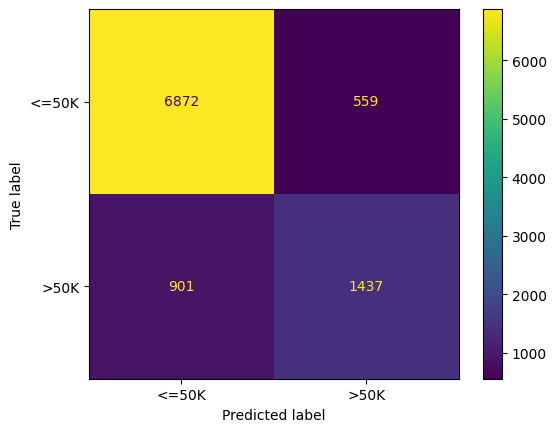

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

mejor = modelos["Random forest"]   # cambie por el algoritmo que usted seleccione
ConfusionMatrixDisplay.from_estimator(mejor, X_test, y_test,
                                      display_labels=["<=50K", ">50K"])

In [13]:
nombres = mejor.named_steps["preparar"].get_feature_names_out()
importancia = mejor.named_steps["modelo"].feature_importances_
pd.Series(importancia, index=nombres).sort_values(ascending=False).head(10)

,0
num__age,0.237404
num__hours-per-week,0.119078
num__capital-gain,0.105794
cat__marital-status_Married-civ-spouse,0.078996
num__education-num,0.065098
cat__relationship_Husband,0.042263
num__capital-loss,0.037032
cat__marital-status_Never-married,0.018863
cat__occupation_Exec-managerial,0.018584
cat__education_Bachelors,0.013422


La importancia de variables solo existe en algoritmos basados en árboles. Para la regresión logística use `mejor.named_steps["modelo"].coef_[0]`.

## D.5 Predicción de un valor (regresión)

Conjunto de viviendas de California: predecir el valor medio de la vivienda de un sector.

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

casas = fetch_california_housing(as_frame=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    casas.data, casas.target, test_size=0.2, random_state=42)

for nombre, reg in {"Regresión lineal": LinearRegression(),
                    "Random forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)}.items():
    reg.fit(Xc_train, yc_train)
    pred = reg.predict(Xc_test)
    print(f"{nombre}: error medio = {mean_absolute_error(yc_test, pred):.3f}  R² = {r2_score(yc_test, pred):.3f}")

El valor está en cientos de miles de dólares: un error de 0,33 significa unos 33.000 dólares.

## D.6 Revisar sesgos

In [ ]:
prueba = X_test.copy()
prueba["real"] = y_test
prueba["predicho"] = mejor.predict(X_test)
prueba.groupby("sex", observed=True)[["real", "predicho"]].mean().round(3)

Compare, para hombres y mujeres, el porcentaje real de ingresos altos y el porcentaje que predice el modelo. Responda: ¿el modelo amplía la diferencia que ya existe en los datos?, ¿qué pasaría si una empresa usara este modelo para decidir créditos o salarios?